STOCK PRICE PREDICTION

stock prediction of Tesla company—this is time series data—data which is dependent on time

tsla.csv -- predict closing price of stock for Tesla -- predict using dependencies of past closing price

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import plotly.express as px
import seaborn as sns

In [3]:
df = pd.read_csv("TSLA.csv")
df.head()

,Date,Open,High,Low,Close,Adj Close,Volume
0,8/16/2016,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,8/17/2016,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,8/18/2016,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,8/19/2016,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,8/22/2016,44.834000,45.021999,44.535999,44.585999,44.585999,10327500


Predict the close of tsla -- we're date and closing stock

In [4]:
#Data prerpocessing
df=df.rename(columns={
    "Date":"date",
    "Open":"open",
    "High":"high",
    "Low":"low",
    "Close":"close",
    "Adj Close":"adj_close",
    "Volume":"volume"
})
df.head()

,date,open,high,low,close,adj_close,volume
0,8/16/2016,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,8/17/2016,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,8/18/2016,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,8/19/2016,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,8/22/2016,44.834000,45.021999,44.535999,44.585999,44.585999,10327500


In [5]:
#date into proper format
df['date']=pd.to_datetime(df.date)
df

,date,open,high,low,close,adj_close,volume
0,2016-08-16,45.098000,45.438000,44.681999,44.722000,44.722000,11335500
1,2016-08-17,44.866001,44.966000,44.560001,44.647999,44.647999,8935500
2,2016-08-18,44.764000,45.132000,44.458000,44.702000,44.702000,8572500
3,2016-08-19,44.708000,45.034000,44.506001,45.000000,45.000000,8297500
4,2016-08-22,44.834000,45.021999,44.535999,44.585999,44.585999,10327500
...,...,...,...,...,...,...,...
1253,2021-08-09,710.169983,719.030029,705.130005,713.760010,713.760010,14715300
1254,2021-08-10,713.989990,716.590027,701.880005,709.989990,709.989990,13432300
1255,2021-08-11,712.710022,715.179993,704.210022,707.820007,707.820007,9800600
1256,2021-08-12,706.340027,722.799988,699.400024,722.250000,722.250000,17459100


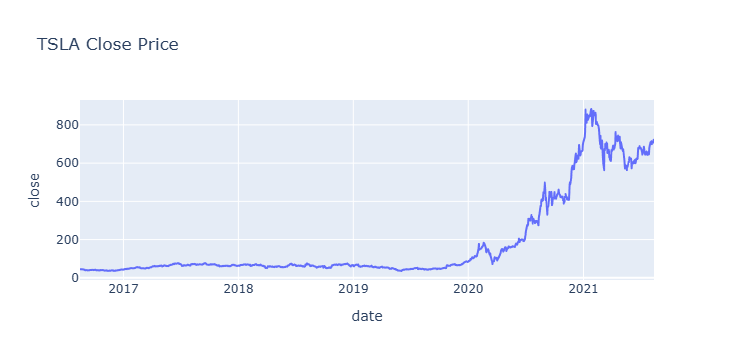

In [8]:
#Using these dates --  plot a simple plo of closing price of stock with respect to date

fig = px.line(df,x='date',y='close',title='TSLA Close Price')
fig.show()

In [11]:
# Create a dataset for ML 
closedf = df[['date','close']]
closedf

,date,close
0,2016-08-16,44.722000
1,2016-08-17,44.647999
2,2016-08-18,44.702000
3,2016-08-19,45.000000
4,2016-08-22,44.585999
...,...,...
1253,2021-08-09,713.760010
1254,2021-08-10,709.989990
1255,2021-08-11,707.820007
1256,2021-08-12,722.250000


In [20]:
#scale price
from sklearn.preprocessing import MinMaxScaler
import numpy as np

sc = MinMaxScaler(feature_range=(0, 1))

closedf = sc.fit_transform(np.array(closedf).reshape(-1, 1))

closedf

array([[0.01053705],
       [0.01044971],
       [0.01051345],
       ...,
       [0.79314193],
       [0.81017257],
       [0.80417701]], shape=(1258, 1))

In [24]:
#split data into training and testing

# we have one column so we cannot use train_test_split
training_size = int(len(closedf)*0.70) # we are having 70% of array
test_size = len(closedf)-training_size 
train_data , test_data = closedf[0:training_size,:], closedf[training_size:len(closedf),:1]

In [25]:
train_data

array([[0.01053705],
       [0.01044971],
       [0.01051345],
       [0.01086515],
       [0.01037654],
       [0.01082738],
       [0.01030336],
       [0.00991153],
       [0.00968257],
       [0.00855191],
       [0.00764078],
       [0.00779893],
       [0.00514578],
       [0.00444001],
       [0.00563204],
       [0.00536766],
       [0.00434087],
       [0.0036587 ],
       [0.00456275],
       [0.00403165],
       [0.00411663],
       [0.00506317],
       [0.00623867],
       [0.00646056],
       [0.00605928],
       [0.00619618],
       [0.0064818 ],
       [0.00672257],
       [0.00708607],
       [0.00633545],
       [0.00644403],
       [0.00512926],
       [0.00591529],
       [0.00819785],
       [0.0076573 ],
       [0.00696097],
       [0.00520007],
       [0.00416383],
       [0.00518827],
       [0.00498763],
       [0.00532045],
       [0.00502068],
       [0.00414023],
       [0.00353832],
       [0.00475159],
       [0.00580435],
       [0.00475159],
       [0.004

In [26]:
test_data

array([[0.14659811],
       [0.16037605],
       [0.17430743],
       [0.17005627],
       [0.17043158],
       [0.15456699],
       [0.14656978],
       [0.14158687],
       [0.11802959],
       [0.11543074],
       [0.13328282],
       [0.13372895],
       [0.13467075],
       [0.12877908],
       [0.12380797],
       [0.10127039],
       [0.11008195],
       [0.10746185],
       [0.09007006],
       [0.08678195],
       [0.06281158],
       [0.05930159],
       [0.04301921],
       [0.05869731],
       [0.05867135],
       [0.06026702],
       [0.07695776],
       [0.0850423 ],
       [0.08242456],
       [0.07916714],
       [0.07628031],
       [0.08144261],
       [0.07142486],
       [0.0650304 ],
       [0.07105899],
       [0.0796109 ],
       [0.08650577],
       [0.08730597],
       [0.09300881],
       [0.11140853],
       [0.12532101],
       [0.13002776],
       [0.13365814],
       [0.135707  ],
       [0.13392958],
       [0.11985185],
       [0.13056593],
       [0.124

In [28]:
# add time spent factor
def create_dataset(dataset,time_step):
    datax,datay = [],[]
    for i in range(len(dataset)-time_step-1):
        a = dataset[i:(i+time_step),0] #i=0,1,2,3,4,5,....,99,100
        datax.append(a)
        datay.append(dataset[i+time_step,0])
    return np.array(datax),np.array(datay)

In [33]:
time_step=50
x_train,y_train = create_dataset(train_data,time_step)
x_test,y_test = create_dataset(test_data,time_step)
print("x_train ",x_train.shape)
print("y_train ",y_train.shape)
print("x_test ",x_test.shape)
print("y_test",y_test.shape)

x_train  (829, 50)
y_train  (829,)
x_test  (327, 50)
y_test (327,)


In [35]:
from xgboost import XGBRegressor
model = XGBRegressor(n_estimator = 1000)
model.fit(x_train,y_train)

C:\Users\aavan\anaconda3\Lib\site-packages\xgboost\training.py:200: UserWarning: [17:18:38] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",None
,feature_types feature_types: typing.Sequence[str] | None.. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [37]:
pred = model.predict(x_test)
print(pred)

[0.15344103 0.1540968  0.1540968  0.14437218 0.14424223 0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968  0.1540968  0.1540968  0.1540968  0.1540968  0.1540968
 0.1540968

In [38]:
#train original
y_test

array([0.13930197, 0.14671142, 0.14231391, 0.12329812, 0.13743014,
       0.13908716, 0.14247914, 0.14187957, 0.15117503, 0.14925598,
       0.14881222, 0.14445719, 0.14737706, 0.14639512, 0.14980833,
       0.14848176, 0.15026389, 0.15310588, 0.15057548, 0.15104521,
       0.15136623, 0.14796246, 0.15485261, 0.16974704, 0.16584286,
       0.16617332, 0.16178762, 0.16681065, 0.1819789 , 0.17979549,
       0.19971296, 0.18738905, 0.1785232 , 0.19165202, 0.18958191,
       0.19186211, 0.19473478, 0.19401247, 0.1924593 , 0.1942202 ,
       0.18455887, 0.19049068, 0.18429686, 0.19600705, 0.2126388 ,
       0.2220381 , 0.24305318, 0.28150965, 0.28582453, 0.28016418,
       0.28686785, 0.32236194, 0.31112855, 0.31578808, 0.32268297,
       0.3119736 , 0.31202082, 0.34557699, 0.32795858, 0.33361658,
       0.31490767, 0.2922308 , 0.32116994, 0.30627313, 0.31161245,
       0.3088696 , 0.29547879, 0.30828187, 0.30875395, 0.30828659,
       0.30936293, 0.30065996, 0.29260138, 0.28217292, 0.32474

In [39]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import math


In [41]:
print("Mean Absolute Error : "+ str(mean_absolute_error(y_test,pred)))
print("Root Mean Squeared Error - MSE : "+str(math.sqrt(mean_squared_error(y_test,pred))))

Mean Absolute Error : 0.42031940601412465
Root Mean Squeared Error - MSE : 0.48460569929768954
